# Computing the kick-out limit for different values of the redshift bin witdth

In this notebook we compute $\xi_{crit}$, i.e. the kick-out limit injection value, for different redshift bins and we test how this changes by changing the redshift bin width.

## Single width case, $\Delta z = 10$

In [6]:
import numpy as np
import local
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import os

# Visual settings
%config InlineBackend.figure_format='retina'
%matplotlib inline

if '/Library/TeX/texbin/' not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + '/Library/TeX/texbin/'
    
# Latex font
plt.rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
plt.rc('text', usetex=True)


%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from matplotlib import colors
#plt.rcParams['figure.figsize'] = [9,7]  # Adjust the size as needed for the plots
from mpl_toolkits.mplot3d import Axes3D

In [7]:
#Fixed parameters for the phi dynamics and injection

logm = -30.50
tf, n = 100, 1
theta_ini = 0.01

eps = 1e-8 
rtol, atol = 1e-5, 1e-7
bphi0_ini, bphi1_ini = theta_ini * tf, 0.



a = np.logspace(-6, 0, 2000)
a_ini = a[0]
z = 1./a - 1.

# Definition of the redsfhift bins
z_bins = [
    (20, 10),
    (30, 20),
    (40, 30),
    (50, 40),
    (60, 50),
    (70, 60),
    (80, 70),
    (90, 80),
    (100, 90),
    #(110, 100),
    #(120, 110),
    #(130, 120),
    #(140, 130),
    #(150, 140)
]

In [8]:
#Defining the functions to search xi_crit before the kick-out for a given z_bin

def is_stable(xi, z_start, z_end):
    """Check whether the axion field stays below the kick-out limit for a given (z_start, z_end) bin."""
    phi = solve_ivp(local.EoM_phi, [a[0], 1], [bphi0_ini, bphi1_ini],
                    t_eval=a, args=[logm, tf, n, xi, eps, z_start, z_end, bphi0_ini],
                    atol=atol, rtol=rtol, method="RK45", max_step=1e-4)

    if not phi.success:
        return False

    # Kick-out happens when the cosine potential peak is overtaken (+- pi * t_f)
    limit_kickout = np.pi * tf
    if np.any(phi.y[0] < -limit_kickout) or np.any(phi.y[0] > limit_kickout):
        return False

    return True


def find_critical_xi(z_start, z_end, xi_min=0.0, xi_max=10.0, tol=1e-5):
    """Binary search for the maximum xi before kick-out, for a given z_bin."""
    low = xi_min
    high = xi_max

    if is_stable(high, z_start, z_end):
        return high

    while (high - low) > tol:
        mid = (low + high) / 2.0
        if is_stable(mid, z_start, z_end):
            low = mid
        else:
            high = mid

    return low



In [9]:
# Loop over the different redshift bins

print(f"Starting search for log10(m_a/eV) = {logm}\n")
critical_values = {}


for z_start, z_end in z_bins:
    print(f"Analyzing bin Delta_z = {z_start} -> {z_end}...")
    
    
    xi_crit = find_critical_xi(z_start, z_end, xi_min=0.0, xi_max=10.0, tol=1e-6)
    
    critical_values[f"{z_start}-{z_end}"] = xi_crit
    print(f"--> Critical kick-out value: xi = {xi_crit:.5e}\n")

Starting search for log10(m_a/eV) = -30.5

Analyzing bin Delta_z = 20 -> 10...
--> Critical kick-out value: xi = 2.39474e-02

Analyzing bin Delta_z = 30 -> 20...
--> Critical kick-out value: xi = 1.71995e-02

Analyzing bin Delta_z = 40 -> 30...
--> Critical kick-out value: xi = 1.58572e-02

Analyzing bin Delta_z = 50 -> 40...
--> Critical kick-out value: xi = 1.58054e-02

Analyzing bin Delta_z = 60 -> 50...
--> Critical kick-out value: xi = 1.62733e-02

Analyzing bin Delta_z = 70 -> 60...
--> Critical kick-out value: xi = 1.70946e-02

Analyzing bin Delta_z = 80 -> 70...
--> Critical kick-out value: xi = 1.80006e-02

Analyzing bin Delta_z = 90 -> 80...
--> Critical kick-out value: xi = 1.90741e-02

Analyzing bin Delta_z = 100 -> 90...
--> Critical kick-out value: xi = 2.01803e-02



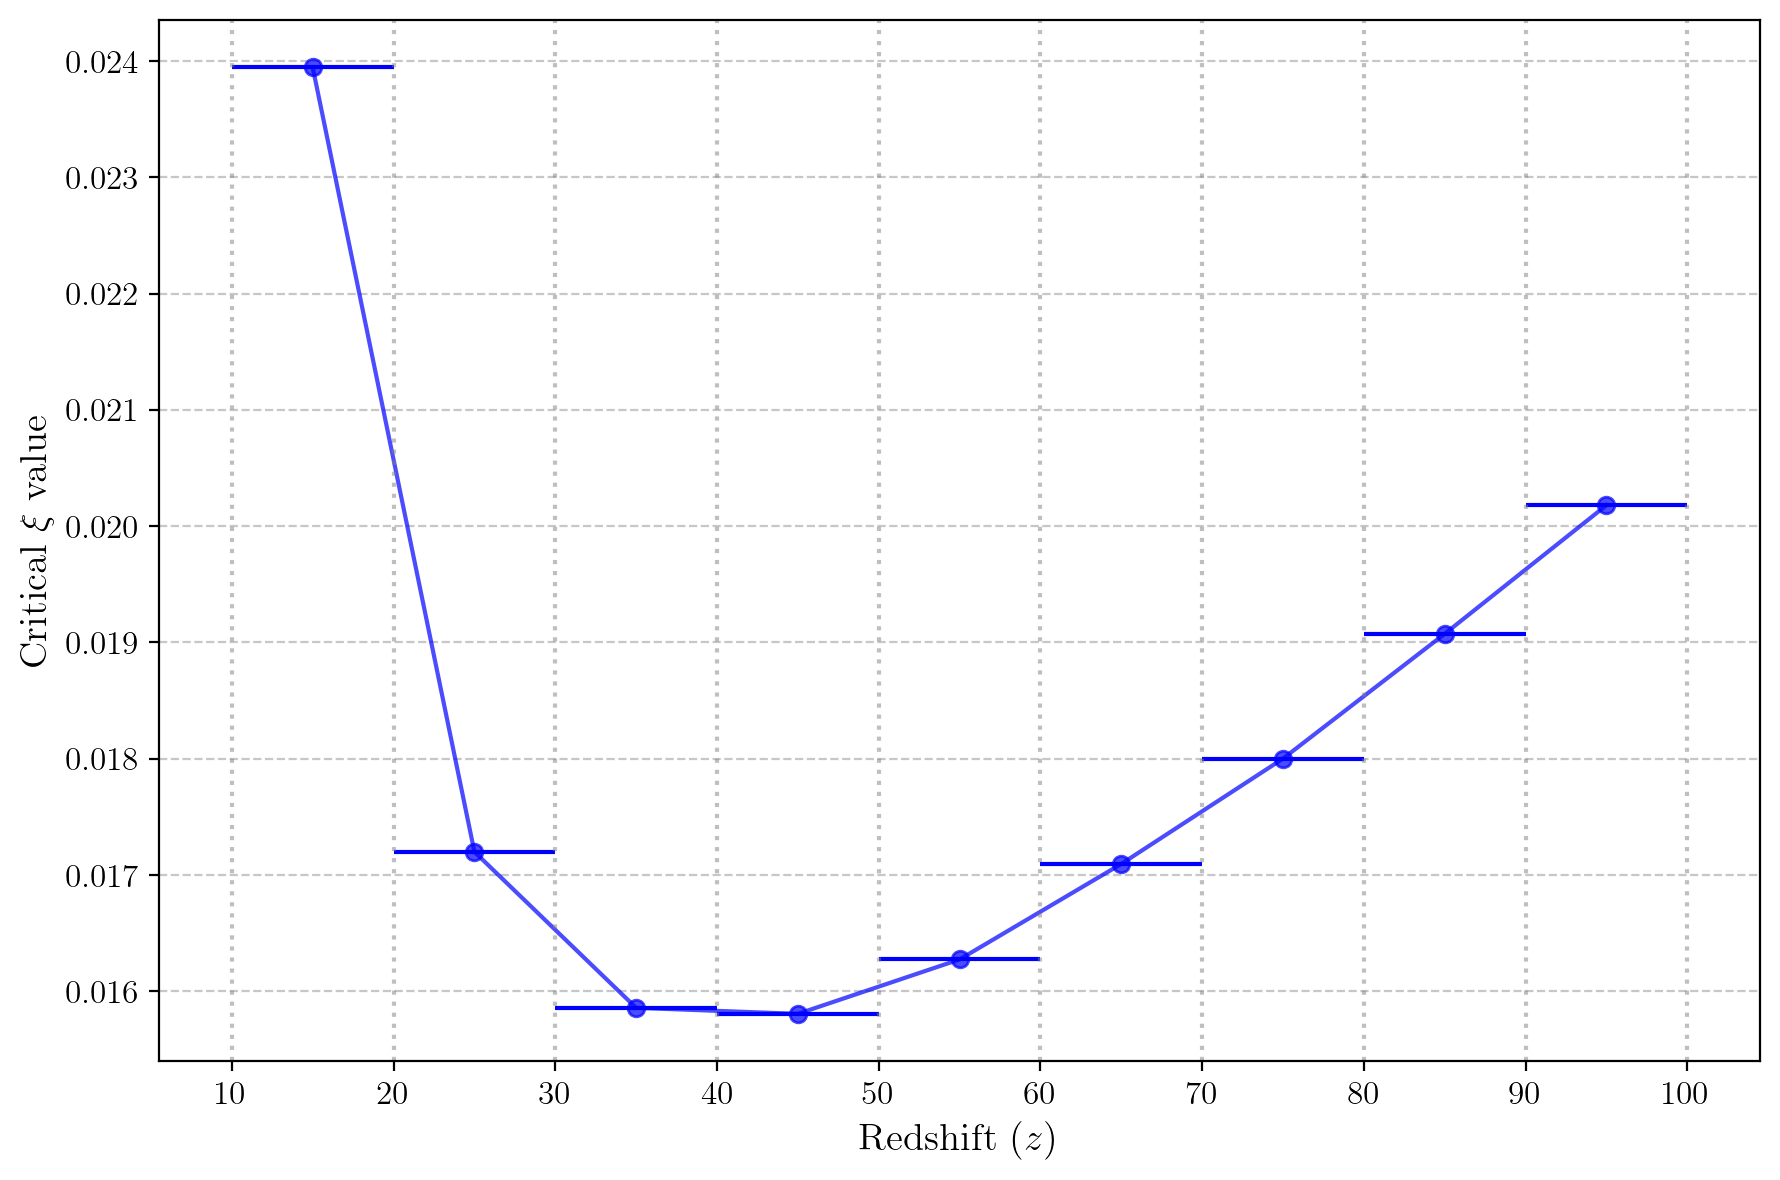

In [10]:
# xi_critical vs \Delta z


xi_values = list(critical_values.values())
z_centers = [(z_start + z_end) / 2.0 for z_start, z_end in z_bins]
z_edges = sorted(list(set([z for bin_tuple in z_bins for z in bin_tuple])))

#Plotting 

plt.figure(figsize=(9, 6))
plt.plot(z_centers, xi_values, marker='o', linestyle='-', color='b', markersize=6, linewidth=1.5, alpha=0.7)
for (z_start, z_end), xi in zip(z_bins, xi_values):
    z_min = min(z_start, z_end)
    z_max = max(z_start, z_end)
    plt.hlines(y=xi, xmin=z_min, xmax=z_max, color='b', linestyle='-', linewidth=1.5)
plt.xlabel('Redshift ($z$)', fontsize=14)
plt.ylabel(r'Critical $\xi$ value', fontsize=14)
plt.xticks(z_edges, fontsize=12)
plt.yticks(fontsize=12)
for edge in z_edges:
    plt.axvline(x=edge, color='gray', linestyle=':', alpha=0.5)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout() 

#plt.savefig("critical_xi_vs_redshift_combined.png", dpi=300)
plt.show()

## Different width cases, $\Delta z = 5,10,15,20,30$

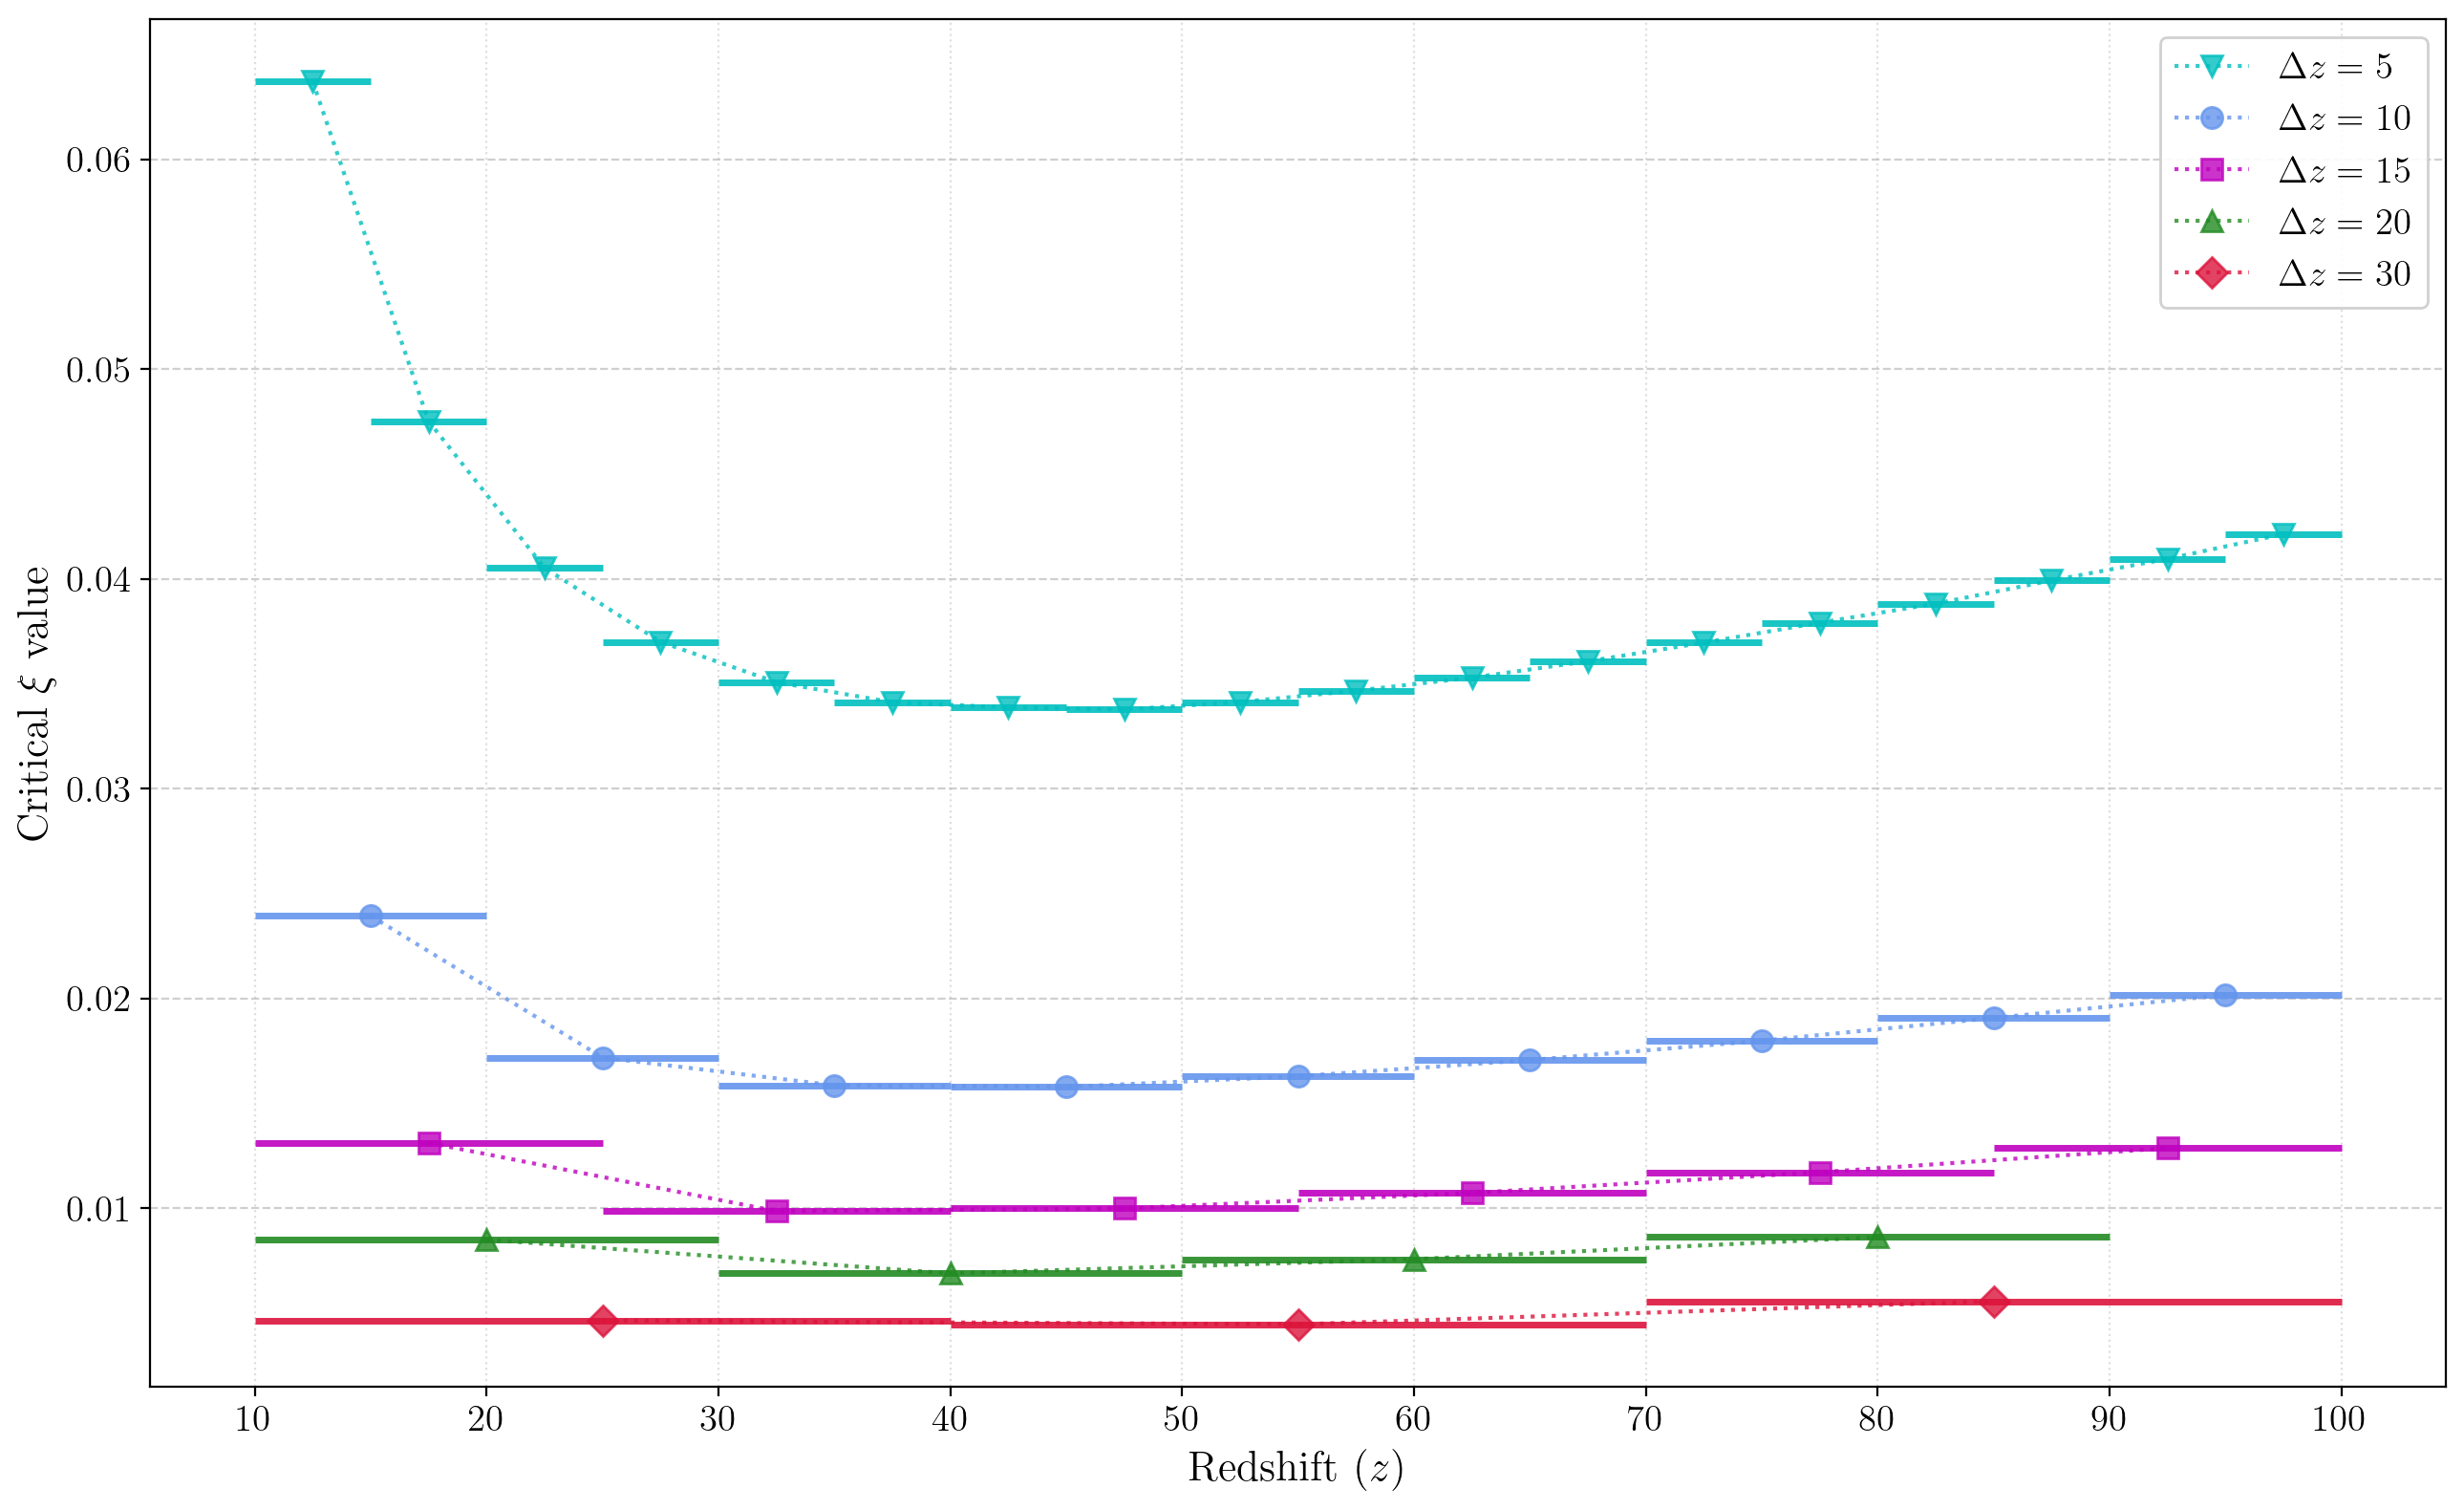

In [13]:
# Run configuration for each Delta z
# Format: Delta_z: {'color': ..., 'marker': ..., 'xi_max': search upper bound}
runs_config = {
    5:  {'color': 'c',              'marker': 'v', 'xi_max': 5.0},
    10: {'color': 'cornflowerblue', 'marker': 'o', 'xi_max': 2.0},
    15: {'color': 'm',              'marker': 's', 'xi_max': 2.0},
    20: {'color': 'forestgreen',    'marker': '^', 'xi_max': 1.0},
    30: {'color': 'crimson',        'marker': 'D', 'xi_max': 1.0}
}

all_results = {}

for dz, config in runs_config.items():
    z_bins = [(z, z - dz) for z in range(10 + dz, 101, dz)]

    results_dz = {}
    for z_start, z_end in z_bins:
        xi_crit = find_critical_xi(z_start, z_end, xi_min=0.0, xi_max=config['xi_max'])
        results_dz[f"{z_start}-{z_end}"] = xi_crit

    all_results[dz] = {
        'bins': z_bins,
        'xi_values': list(results_dz.values()),
        'z_centers': [(zs + ze) / 2.0 for zs, ze in z_bins]
    }


# Master plot
plt.figure(figsize=(13, 8))

for dz, config in runs_config.items():
    data = all_results[dz]
    c = config['color']

    plt.plot(data['z_centers'], data['xi_values'], marker=config['marker'], linestyle=':',
             color=c, markersize=8, linewidth=1.5, alpha=0.8, label=rf'$\Delta z = {dz}$')

    for (z_start, z_end), xi in zip(data['bins'], data['xi_values']):
        plt.hlines(y=xi, xmin=min(z_start, z_end), xmax=max(z_start, z_end),
                   color=c, linestyle='-', linewidth=2.5, alpha=0.9)

plt.xlabel('Redshift ($z$)', fontsize=16)
plt.ylabel(r'Critical $\xi$ value', fontsize=16)

plt.xticks(np.arange(10, 101, 10), fontsize=14)
plt.yticks(fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.grid(axis='x', linestyle=':', alpha=0.4)

plt.legend(fontsize=14, loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.savefig("master_critical_xi_all_deltas.png", dpi=300)
plt.show()